# Project: Investigate data

**Data set:** `movies.csv` (main table) and `genre_groups.csv` (second table), from the vega-datasets collection.

**Environment:** Python 3.14.10, pandas 3.0.5, scipy 1.18.1, matplotlib 3.11.2, seaborn 0.13.2.

Loosely formed plan: understand, clean, merge, describe, draw, answer, check the source.

**Warning: Required library!** The library `scipy` must be installed before this notebook is run (`pip install scipy`). The notebook does not import it, but `pandas` uses it internally to calculate Spearman's rank correlation, which is used in Part 7 and in Part 8 (chart 1). Without it, those cells fail with `ModuleNotFoundError`. The `pandas` library lists `scipy` only as an optional dependency, so installing `pandas` does not install it automatically.

In [ ]:
import sys
import importlib.util
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)

if importlib.util.find_spec("scipy") is None:
    raise ModuleNotFoundError("SciPy is required (pandas uses it for Spearman's correlation): pip install scipy")

Python: 3.14.10
Pandas: 3.0.5


## Part 1: Read and understand the data

In [ ]:
movies_raw = pd.read_csv("data/movies.csv", parse_dates=["Release Date"], date_format="%b %d %Y")
genres = pd.read_csv("data/genre_groups.csv")

movies = movies_raw.copy()

print(f"{movies.shape[0]} rows, {movies.shape[1]} columns")

display(movies.dtypes)

display(movies.sample(10, random_state=1))

3201 rows, 16 columns


Title                                str
US Gross                         float64
Worldwide Gross                  float64
US DVD Sales                     float64
Production Budget                float64
Release Date              datetime64[us]
MPAA Rating                          str
Running Time min                 float64
Distributor                          str
Source                               str
Major Genre                          str
Creative Type                        str
Director                             str
Rotten Tomatoes Rating           float64
IMDB Rating                      float64
IMDB Votes                       float64
dtype: object

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
1751,Firestorm,8123860.0,8123860.0,NaN,19000000.0,1998-01-09,R,NaN,20th Century Fox,Original Screenplay,Action,Contemporary Fiction,NaN,NaN,4.4,2118.0
909,Star Trek: Generations,75671262.0,120000000.0,NaN,38000000.0,1994-11-18,PG,NaN,Paramount Pictures,Based on TV,Adventure,Science Fiction,NaN,NaN,6.5,26465.0
979,Trois,1161843.0,1161843.0,NaN,200000.0,2000-02-11,NC-17,NaN,Rainforest Productions,Original Screenplay,Thriller/Suspense,Contemporary Fiction,NaN,NaN,3.3,360.0
329,Fled,17192205.0,19892205.0,NaN,30000000.0,1996-07-19,R,98.0,MGM,Original Screenplay,Action,Contemporary Fiction,NaN,14.0,4.9,4215.0
1885,Ghost World,6217849.0,8764007.0,NaN,5500000.0,2001-07-20,R,NaN,MGM,Based on Comic/Graphic Novel,Comedy,Contemporary Fiction,Terry Zwigoff,92.0,7.7,42973.0
1967,How to Deal,14108518.0,14108518.0,NaN,16000000.0,2003-07-18,PG-13,NaN,New Line,Based on Book/Short Story,Drama,Contemporary Fiction,NaN,29.0,5.4,5292.0
2131,K-PAX,50315140.0,50315140.0,NaN,48000000.0,2001-10-26,PG-13,121.0,Universal,Based on Book/Short Story,Drama,Science Fiction,Iain Softley,40.0,7.3,50475.0
98,Beverly Hills Cop III,42586861.0,119180938.0,NaN,50000000.0,1994-05-25,R,NaN,Paramount Pictures,Original Screenplay,Action,Contemporary Fiction,John Landis,10.0,5.0,21199.0
340,Forrest Gump,329694499.0,679400525.0,NaN,55000000.0,1994-07-06,PG-13,NaN,Paramount Pictures,Based on Book/Short Story,Drama,Historical Fiction,Robert Zemeckis,70.0,8.6,300455.0
1012,The Work and the Glory,3347647.0,3347647.0,NaN,7500000.0,2004-11-24,PG,NaN,Excel Entertainment,Based on Book/Short Story,Drama,Contemporary Fiction,NaN,17.0,6.0,531.0


In [ ]:
movies.info()


<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Title                   3200 non-null   str           
 1   US Gross                3194 non-null   float64       
 2   Worldwide Gross         3194 non-null   float64       
 3   US DVD Sales            564 non-null    float64       
 4   Production Budget       3200 non-null   float64       
 5   Release Date            3201 non-null   datetime64[us]
 6   MPAA Rating             2596 non-null   str           
 7   Running Time min        1209 non-null   float64       
 8   Distributor             2969 non-null   str           
 9   Source                  2836 non-null   str           
 10  Major Genre             2926 non-null   str           
 11  Creative Type           2755 non-null   str           
 12  Director                1870 non-null   str           
 13 

In [ ]:
overview = pd.DataFrame({
    "dtype": movies.dtypes,
    "non_null": movies.notna().sum(),
    "unique": movies.nunique(),
    "example": movies.apply(lambda col: col.dropna().iloc[0]),
})
overview

,dtype,non_null,unique,example
Title,str,3200,3176,The Land Girls
US Gross,float64,3194,3060,146083.0
Worldwide Gross,float64,3194,3074,146083.0
US DVD Sales,float64,564,564,3479242.0
Production Budget,float64,3200,381,8000000.0
Release Date,datetime64[us],3201,1600,1998-06-12 00:00:00
MPAA Rating,str,2596,7,R
Running Time min,float64,1209,109,104.0
Distributor,str,2969,174,Gramercy
Source,str,2836,18,Original Screenplay


In [ ]:
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(movies.describe())

,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,Running Time min,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
count,"3,194.00","3,194.00",564.00,"3,200.00",3201,"1,209.00","2,321.00","2,988.00","2,988.00"
mean,"44,002,085.16","85,343,400.14","34,901,546.82","31,069,171.45",1998-12-06 23:41:06.354264,110.19,54.34,6.28,"29,908.64"
min,0.00,0.00,"618,454.00",218.00,1928-12-31 00:00:00,46.00,1.00,1.40,18.00
25%,"5,493,221.25","8,031,285.25","9,906,210.75","6,575,000.00",1996-09-20 00:00:00,95.00,30.00,5.60,"4,828.50"
50%,"22,019,465.50","31,168,926.50","20,331,557.50","20,000,000.00",2001-12-14 00:00:00,107.00,55.00,6.40,"15,106.00"
75%,"56,091,761.50","97,283,797.00","37,794,215.75","42,000,000.00",2005-12-16 00:00:00,121.00,80.00,7.20,"35,810.50"
max,"760,167,650.00","2,767,891,499.00","352,582,053.00","300,000,000.00",2046-12-31 00:00:00,222.00,100.00,9.20,"519,541.00"
std,"62,555,311.39","149,947,342.89","45,895,121.60","35,585,913.44",NaN,20.17,28.08,1.25,"44,937.58"


In [ ]:
movies.describe(include=["object", "string"])

,Title,MPAA Rating,Distributor,Source,Major Genre,Creative Type,Director
count,3200,2596,2969,2836,2926,2755,1870
unique,3176,7,174,18,12,9,550
top,"20,000 Leagues Under the Sea",R,Warner Bros.,Original Screenplay,Drama,Contemporary Fiction,Steven Spielberg
freq,2,1194,318,1536,789,1453,23


In [ ]:
for col in ["MPAA Rating", "Major Genre", "Source", "Creative Type"]:
    display(movies[col].value_counts(dropna=False))

MPAA Rating
R            1194
PG-13         865
NaN           605
PG            354
Not Rated      94
G              79
NC-17           8
Open            2
Name: count, dtype: int64

Major Genre
Drama                  789
Comedy                 675
Action                 420
NaN                    275
Adventure              274
Thriller/Suspense      239
Horror                 219
Romantic Comedy        137
Musical                 53
Documentary             43
Western                 36
Black Comedy            36
Concert/Performance      5
Name: count, dtype: int64

Source
Original Screenplay              1536
Based on Book/Short Story         657
NaN                               365
Based on Real Life Events         186
Remake                            126
Based on TV                       106
Based on Comic/Graphic Novel       82
Based on Play                      55
Based on Game                      22
Traditional/Legend/Fairytale       16
Based on Magazine Article          10
Based on Musical/Opera              9
Based on Short Film                 8
Spin-Off                            8
Based on Factual Book/Article       6
Disney Ride                         4
Compilation                         3
Based on Toy                        1
Musical Group Movie                 1
Name: count, dtype: int64

Creative Type
Contemporary Fiction       1453
NaN                         446
Historical Fiction          350
Fantasy                     265
Science Fiction             243
Dramatization               204
Kids Fiction                141
Factual                      49
Super Hero                   49
Multiple Creative Types       1
Name: count, dtype: int64

### What the data is

**One row is one film** (a release). The table has 3,201 rows and 16 columns. Some titles appear twice (24 repeated titles), but the ones checked appear to be remakes with different release dates, so they are separate rows.

**Columns we will use:**
| Column | Type | Meaning | Why |
|---|---|---|---|
| Title | text | film title | to identify rows |
| Release Date | datetime64 | release date | year, decades, and spotting date errors |
| Production Budget | number | budget (currency not stated) | budget versus earnings |
| US Gross, Worldwide Gross | number | box office (currency not stated) | budget versus earnings, genre comparison |
| Rotten Tomatoes Rating | number, 1–100 | critics' score | critics versus audiences |
| IMDB Rating | number, 1.4–9.2 | audience score | critics versus audiences, genre comparison |
| IMDB Votes | number | number of votes | to judge how reliable a rating is |
| Major Genre | text, 12 values | genre | merge key, genre comparison |

**Columns we will probably not use:** US DVD Sales, Running Time min, Director, Distributor, Source, Creative Type, and MPAA Rating. Most of them have a lot of missing values.

**Not stated in the data:** the currency and year of the money columns, and the date on which the ratings were collected.

#### Tentative questions

These are the questions we plan to answer. They are tentative: cleaning and missing values may change how many films we can use for each one, and we may adjust the wording after that.

1. **Budget and earnings.** Do films with a bigger production budget earn more at the box office?
   *(Production Budget, Worldwide Gross)*
2. **Critics and audiences.** Do critics and audiences rate films alike?
   *(Rotten Tomatoes Rating, IMDB Rating; the two scales must be made comparable first)*
3. **Genres.** How do the genre groups differ in ratings and in money?
   *(Genre group from the second table, ratings, gross)*


## Part 2: Clean the data

### Problem 1: release dates in the future

**Problem.** There are several movies in this dataset with release dates in the future. But, since the site for vega-datasets doesn't identify either the source of this dataset. nor the date when it was made, we'll have to do some manual checking. Examination of a few entries in the dataset, and checking them against the IMDB, shows that movies with release dates before 2010 appear to have correct release dates. So we'll check the moviess with release dates after year 2010 to determine the most likely cut-off date.

In [ ]:
# Columns that might help us identify a particular movie
ID_COLS = ["Title", "Release Date", "Director", "Running Time min", "Distributor"]

def films_in_years(df, first=None, last=None, cols=ID_COLS):
    """Films released from year `first` to year `last` (both inclusive), oldest first.
    Leave one out to get 'from first onward' or 'up to last'."""
    year = df["Release Date"].dt.year
    mask = pd.Series(True, index=df.index)
    if first is not None:
        mask &= year >= first
    if last is not None:
        mask &= year <= last
    return df.loc[mask, cols].sort_values("Release Date")

print(len(films_in_years(movies, last=2010)))
display(films_in_years(movies, first=2011, last=2014))
display(films_in_years(movies, first=2015))


3177


,Title,Release Date,Director,Running Time min,Distributor
2658,Restless,2011-01-28,NaN,NaN,Sony Pictures
2967,The Adventures of Tintin: Secret of the Unicorn,2011-12-23,Steven Spielberg,NaN,Paramount Pictures


,Title,Release Date,Director,Running Time min,Distributor
120,The Birth of a Nation,2015-02-08,NaN,NaN,NaN
467,Intolerance,2016-09-05,NaN,NaN,NaN
26,"20,000 Leagues Under the Sea",2016-12-24,NaN,NaN,NaN
15,Over the Hill to the Poorhouse,2020-09-17,NaN,NaN,NaN
102,The Big Parade,2025-01-01,King Vidor,NaN,MGM
85,Ben-Hur,2025-12-30,NaN,NaN,MGM
1028,Wings,2027-08-12,NaN,NaN,NaN
822,She Done Him Wrong,2033-02-09,NaN,NaN,NaN
33,42nd Street,2033-03-09,NaN,NaN,Warner Bros.
495,King Kong (1933),2033-04-07,NaN,100.0,NaN


Checking both IMDB and Wikipedia, we can see that "The Adventures of Tintin" was released in 2011, and so was "Restless" distributed by Sony. We can also find "The Birth of a Nation" from 1915, and "Intolerance" from 1916. As to the "20,000 Leagues Under the Sea", there have been numerous productions of this story, and one of them was released in 1916, and none was released in 2016. From this we conclude that the most likely cut-off year is 2011, and everything in the dataset with the release date after this year is likely 100 years off. The fact that there are no movies in this dataset with release year between 2012 and 2014 can also be interpreted as supporting the conclusion.

#### Dates in the future

The data source [vega-datasets](https://vega.github.io/vega-datasets/datasets/movies/) doesn't say when the data was collected. To decide where the cut-off really is, we listed the films dated 2010-2012 and 2011-2016 with director, running time, and distributor, and checked a selection by hand against IMDB and Wikipedia.

- Films up to 2010 (3177 rows): four movies checked ("Firestorm", "Star Trek: Generations", "Forrest Gump", "K-PAX") -- all four appear with the correct release date.
- 2011 (2 rows): both movies appear to have correct release dates.
- 2015 and later (22 rows): four movies checked ("The Birth of a Nation", "Intolerance", "20,000 Leagues Under the Sea", "Duel in the Sun") -- all four apear to have the release date 100 years off.

**Decision:** subtract 100 years from the 22 rows dated 2015 or later; leave the rows with release date before 2011 unchanged.

In [ ]:
century = movies["Release Date"].dt.year >= 2015
movies.loc[century, "Release Date"] = movies.loc[century, "Release Date"] - pd.DateOffset(years=100)
print(century.sum(), movies["Release Date"].min(), movies["Release Date"].max())

22 1915-02-08 00:00:00 2011-12-23 00:00:00


### Problem 2: garbled accents in titles

Some titles contain characters that appear to be misplaced (e.g. `È` in "LÈon"), which looks like text-encoding damage. This problem was not visible in the summaries of Part 1; it was found by manually examining the `Title` values. The next cells isolate the titles with non-ASCII characters and test one explanation for the damage.

In [ ]:
non_ascii = movies["Title"].str.contains(r"[^\x00-\x7f]", na=False)
print(non_ascii.sum())
movies.loc[non_ascii, ["Title", "Release Date", "Distributor"]]

20


,Title,Release Date,Distributor
40,AstÈrix aux Jeux Olympiques,2008-07-04,Alliance
113,De battre mon coeur s'est arrÍtÈ,2005-07-01,WellSpring
137,Les BronzÈs 3: amis pour la vie,2006-02-01,NaN
316,Per qualche dollaro in pi˘,1967-05-10,MGM
460,I Love You Ö Don't Touch Me!,1998-02-20,MGM
534,Alien³,1992-05-22,20th Century Fox
648,The Naked Gun 2Ω: The Smell of Fear,1991-06-28,Paramount Pictures
729,LÈon,1994-11-18,Sony Pictures
763,Ri¢hie Ri¢h,1994-12-21,Warner Bros.
1163,Le Fabuleux destin d'AmÈlie Poulain,2001-11-02,Miramax


In [ ]:
chars = sorted(set("".join(movies.loc[non_ascii, "Title"])) - set(map(chr, range(128))))

rows = []
for c in chars:
    try:
        b = c.encode("mac_roman")          # the byte this character would have in Mac OS Roman
        rows.append((c, b.hex(), b.decode("cp1252", errors="replace"), b.decode("latin-1")))
    except UnicodeEncodeError:             # the character does not exist in Mac OS Roman
        rows.append((c, "-", "(not in Mac Roman)", "-"))

pd.DataFrame(rows, columns=["char", "mac_roman_byte", "as_cp1252", "as_latin1"])

,char,mac_roman_byte,as_cp1252,as_latin1
0,¢,a2,¢,¢
1,³,-,(not in Mac Roman),-
2,·,e1,á,á
3,È,e9,é,é
4,Ë,e8,è,è
5,Í,ea,ê,ê
6,Î,eb,ë,ë
7,Ö,85,…,
8,Ù,f4,ô,ô
9,Û,f3,ó,ó


20 titles contain non-ASCII characters (two cells above). Most of the characters in the table (`È`, `Í`, `Ö`, `Ω`, ...) are not plausible in a that position in a film title, but each of them turns into a plausible character (`é`, `ê`, `…`, `½`) when the Mac OS Roman byte it corresponds to is read as Windows-1252. This is consistent with text that was written as Windows-1252 and read as Mac OS Roman. The cause is inferred from this pattern and is not documented in the source.

Windows-1252 was chosen over Latin-1 because they differ for byte `85` (`Ö` in the data): Windows-1252 gives `…`, Latin-1 gives an invisible control character (last column).

Two characters do not follow the pattern: `³` does not exist in Mac OS Roman, and `¢` is unchanged by the conversion.

**Next:** the titles are re-encoded with Mac OS Roman and decoded with Windows-1252. Titles that cannot be re-encoded are left as they are.

In [ ]:
def fix_text(s):
    """Repair text that was written as Windows-1252 but read as Mac OS Roman."""
    try:
        # encoding with mac_roman recovers the original bytes;
        # decoding with cp1252 reads them the way they were written
        return s.encode("mac_roman").decode("cp1252")
    except UnicodeError:
        return s    # characters that Mac Roman cannot encode: left unchanged

before = movies["Title"].copy()
movies["Title"] = movies["Title"].map(fix_text, na_action="ignore")
changed = movies["Title"].fillna("") != before.fillna("")

print(changed.sum())
print(movies.loc[non_ascii & ~changed, "Title"].tolist())
pd.DataFrame({"before": before[changed], "after": movies.loc[changed, "Title"]})

18
['Alien³', 'Ri¢hie Ri¢h']


,before,after
40,AstÈrix aux Jeux Olympiques,Astérix aux Jeux Olympiques
113,De battre mon coeur s'est arrÍtÈ,De battre mon coeur s'est arrêté
137,Les BronzÈs 3: amis pour la vie,Les Bronzés 3: amis pour la vie
316,Per qualche dollaro in pi˘,Per qualche dollaro in più
460,I Love You Ö Don't Touch Me!,I Love You … Don't Touch Me!
648,The Naked Gun 2Ω: The Smell of Fear,The Naked Gun 2½: The Smell of Fear
729,LÈon,Léon
1163,Le Fabuleux destin d'AmÈlie Poulain,Le Fabuleux destin d'Amélie Poulain
1168,AimÈe & Jaguar,Aimée & Jaguar
1251,La mala educaciÛn,La mala educación


18 titles were changed. All 18 results are readable titles (e.g. `LÈon` --> `Léon`, `La mala educaciÛn` --> `La mala educación`). The 2 titles that were not changed (`Alien³`, `Ri¢hie Ri¢h`) are correct as they stand, which agrees with the table above. The titles without non-ASCII characters were not touched.

### Problem 3: zeros in the gross columns

Identified in Part 1: `.describe()` shows a minimum of 0 for both `US Gross` and `Worldwide Gross`. A gross of exactly 0 is suspect: it may mean "no figure available" and not "earned nothing".

The next cells count the zeros, show how they overlap between the two columns, and show when the films were released.

In [ ]:
# Count zeros
gross = ["US Gross", "Worldwide Gross"]
pd.DataFrame({"zeros": (movies[gross] == 0).sum(), "missing": movies[gross].isna().sum()})

,zeros,missing
US Gross,66,7
Worldwide Gross,47,7


In [ ]:
# Overlap between columns
us0 = movies["US Gross"] == 0
ww0 = movies["Worldwide Gross"] == 0
pd.crosstab(us0, ww0, rownames=["US Gross is 0"], colnames=["Worldwide Gross is 0"])

Worldwide Gross is 0,False,True
US Gross is 0,,
False,3135,0
True,19,47


In [ ]:
any0 = us0 | ww0
decade = movies["Release Date"].dt.year // 10 * 10
by_decade = any0.groupby(decade).agg(zero_rows="sum", no_of_films="size")
by_decade["share"] = (by_decade["zero_rows"] / by_decade["no_of_films"]).round(2)
by_decade

,zero_rows,no_of_films,share
Release Date,,,
1910,0,3,0.00
1920,0,6,0.00
1930,1,15,0.07
1940,1,19,0.05
1950,2,38,0.05
1960,8,71,0.11
1970,1,100,0.01
1980,1,256,0.00
1990,1,769,0.00


In [ ]:
movies.loc[any0 & (movies["Release Date"].dt.year >= 2010),
           ["Title", "Release Date", "Production Budget", "US Gross", "Worldwide Gross"]]

,Title,Release Date,Production Budget,US Gross,Worldwide Gross
1907,How Do You Know?,2010-12-17,90000000.0,0.0,0.0
2402,Shinjuku Incident,2010-02-05,25000000.0,0.0,0.0
2658,Restless,2011-01-28,15000000.0,0.0,0.0
2967,The Adventures of Tintin: Secret of the Unicorn,2011-12-23,130000000.0,0.0,0.0


- `US Gross` contains 66 zeros and `Worldwide Gross` 47 (7 values are missing in each column).
- All 47 rows with a worldwide gross of 0 also have a US gross of 0. In a further 19 rows, the US gross is 0 while the worldwide gross is above 0. If the worldwide gross includes the US gross (the data does not say), a US zero next to a positive worldwide figure cannot be a measured value, so in these rows the zero stands for "no figure".
- In total, 66 rows have a zero in at least one column. Zeros occur in every decade from the 1930s onward; 47 of the 66 are from the 2000s, the decade with the most films (1,830 films).
- 4 of the zero rows are dated 2010 or later; 2 of them are dated 2011 -- the year of collection (see Problem 1).

**Decision:** the zeros are replaced by missing values in both columns. A zero cannot be told apart from "no figure" in this data, and it would pull down means and medians. Keeping the zeros was rejected because of the 19 rows above.

In [ ]:
na_before = movies[gross].isna().sum()
movies[gross] = movies[gross].replace(0, np.nan)
na_after = movies[gross].isna().sum()

print((movies[gross] == 0).sum().to_dict())
pd.DataFrame({"missing before": na_before, "missing after": na_after, "changed": na_after - na_before})

{'US Gross': 0, 'Worldwide Gross': 0}


,missing before,missing after,changed
US Gross,7,73,66
Worldwide Gross,7,54,47


66 values in `US Gross` and 47 in `Worldwide Gross` were changed from 0 to missing, and no zeros remain. `US Gross` now has 73 missing values and `Worldwide Gross` 54 (7 each were missing before). Rows without a gross are left out only of the calculations that need it.

### Further checks: Duplicates and extra spaces

In [ ]:
text_cols = movies.select_dtypes(include=["object", "string"]).columns
padded = pd.Series({col: (movies[col].dropna() != movies[col].dropna().str.strip()).sum()
                    for col in text_cols})
padded

Title            0
MPAA Rating      0
Distributor      0
Source           0
Major Genre      0
Creative Type    0
Director         0
dtype: int64

In [ ]:
print(movies.duplicated().sum())
print(movies.duplicated(subset=["Title", "Release Date"]).sum())
print(movies["Title"].duplicated(keep=False).sum())

0
0
48


**Leading and trailing spaces.** All 7 text columns were checked, and no value has spaces at the start or end (0 rows in every column).

**Duplicates.** No row is repeated in every column (0 rows), and no title occurs twice with the same release date (0 rows). 48 rows share their title with another row, but with a different release date, so they represent different releases and are kept.

**Result:** nothing needs to be done for either check.

## Part 3: Missing values

The missing values are counted in every column, then examined to see where they occur and what they may mean. Decisions are made for the columns that matter for the questions.

In [ ]:
# Count missing values per column
missing = pd.DataFrame({
    "missing": movies.isna().sum(),
    "percent": (movies.isna().mean() * 100).round(1),
}).sort_values("missing", ascending=False)

missing

,missing,percent
US DVD Sales,2637,82.4
Running Time min,1992,62.2
Director,1331,41.6
Rotten Tomatoes Rating,880,27.5
MPAA Rating,605,18.9
Creative Type,446,13.9
Source,365,11.4
Major Genre,275,8.6
Distributor,232,7.2
IMDB Rating,213,6.7


In [ ]:
# Check where the missing values occur
# Each cell in the result is the share of missing values for that column in that decade
decade = movies["Release Date"].dt.year // 10 * 10
with_missing = movies.columns[movies.isna().any()]
share = movies[with_missing].isna().groupby(decade).mean().round(2)

display(share.T)
# Film counts per decade
decade.value_counts().sort_index().to_frame("films").T

Release Date,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010
Title,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
US Gross,0.33,0.33,0.07,0.05,0.05,0.11,0.05,0.00,0.00,0.03,0.04
Worldwide Gross,0.33,0.33,0.07,0.05,0.05,0.10,0.05,0.00,0.00,0.02,0.04
US DVD Sales,1.00,1.00,1.00,0.95,0.97,1.00,0.96,0.98,1.00,0.71,0.70
Production Budget,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
MPAA Rating,1.00,1.00,0.87,0.95,0.87,0.87,0.82,0.88,0.15,0.02,0.15
Running Time min,1.00,1.00,0.80,1.00,1.00,1.00,1.00,0.98,0.60,0.52,0.71
Distributor,1.00,0.50,0.27,0.58,0.50,0.45,0.35,0.08,0.03,0.04,0.07
Source,0.33,0.50,0.40,0.63,0.61,0.58,0.46,0.17,0.07,0.06,0.23
Major Genre,0.33,0.50,0.33,0.68,0.66,0.55,0.44,0.07,0.05,0.04,0.15


Release Date,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010
films,3,6,15,19,38,71,100,256,769,1830,94


In [ ]:
# Check missing values overlaps
both = movies[["Rotten Tomatoes Rating", "IMDB Rating"]].notna().all(axis=1)
rt_missing_imdb_present = movies["Rotten Tomatoes Rating"].isna() & movies["IMDB Rating"].notna()
imdb_together = (movies["IMDB Rating"].isna() == movies["IMDB Votes"].isna()).all()

print("both ratings present:", both.sum())
print("Rotten Tomatoes missing, IMDB present:", rt_missing_imdb_present.sum())
print("IMDB Rating and IMDB Votes always missing together:", imdb_together)

both ratings present: 2260
Rotten Tomatoes missing, IMDB present: 728
IMDB Rating and IMDB Votes always missing together: True


Every column except `Release Date` has missing values. Four columns are missing in more than a quarter of the rows: `US DVD Sales` (82.4%), `Running Time min` (62.2%), `Director` (41.6%) and `Rotten Tomatoes Rating` (27.5%). `IMDB Rating` and `IMDB Votes` are missing in exactly the same 213 rows.

**US DVD Sales.** The value is missing for 95–100% of the films in every decade before 2000, but also for 71% of the films in the 2000s and 70% in the 2010s. The figure was therefore recorded for only some films, and a missing value cannot be read as zero sales. A likely part of the explanation for the old films is that DVDs did not exist yet; the reason for the gaps in later decades is unknown.  
*Decision: the column is dropped. It is mostly empty, it is not needed for the questions, and filling it would be guessing.*

**Rotten Tomatoes Rating.** The missing values are spread over all decades (18–41% of the films in each), so this is not only a problem of old films. 728 films have an IMDB rating but no Rotten Tomatoes rating, and 2,260 films have both. The reason is unknown; the source does not say how the films were matched.  
*Decision: the values are kept as missing and are not filled in. Question 2 (critics and audiences) uses only the 2,260 films that have both ratings, and the answer applies only to those films.*

**IMDB Rating and IMDB Votes.** Both are missing for 0–20% of the films in every decade from the 1920s onward (14% in the 2010s), and for 67% in the 1910s, which have only 3 films. The 213 films without an IMDB rating also drop out of question 2, in addition to the Rotten Tomatoes gaps counted above.  
*Decision: the values are kept as missing.*

**Major Genre.** The genre is missing for 33–68% of the films before 1980, but only 4–7% from the 1980s to the 2000s (15% in the 2010s). The genre comparison will therefore cover older films less well than newer ones.  
*Decision: the values are kept as missing here. Rows without a genre cannot be matched to the genre groups; how to label them is decided at the merge (Part 4).*

**Creative Type (446 missing, 13.9%).** The pattern is similar to `Major Genre`: 63–100% missing in every decade before 1980, 8–12% in the 1980s to the 2000s, and 26% in the 2010s. The column is not used for the three questions and is left unchanged. If it is used later, the same limitation applies as for the genre.

**Gross columns.** `US Gross` (73) and `Worldwide Gross` (54) are missing after Problem 3 replaced the zeros.  
*Decision: kept as missing (see Problem 3).*

**Other columns.** `Running Time min`, `Director`, `MPAA Rating`, `Source` and `Distributor` are not used for the three questions and are left unchanged. `Title` and `Production Budget` are missing in one row each, which is kept; the row simply drops out of any calculation that needs the missing value.

In [ ]:
shape_before = movies.shape
movies = movies.drop(columns="US DVD Sales")
print(shape_before, "->", movies.shape)

(3201, 16) -> (3201, 15)


`US DVD Sales` was dropped: the table went from 16 to 15 columns, and no rows were removed. All other missing values are kept as described above.

## Part 4: Merge with the second table

The dataset `genre_groups.csv` puts the genres of `Major Genre` into groups (column `Genre group`). According to the project description it was made for this project. The merge adds the group to every film and is needed for question 3 (genres compared in ratings and money). The merge key is `Major Genre`. Before merging, the table and the key are examined.

In [ ]:
# Examine the second table
print(genres.shape, genres["Genre group"].nunique())
genres

(12, 2) 5


,Major Genre,Genre group
0,Drama,Drama
1,Comedy,Comedy & music
2,Romantic Comedy,Comedy & music
3,Black Comedy,Comedy & music
4,Musical,Comedy & music
5,Action,Action & adventure
6,Adventure,Action & adventure
7,Western,Action & adventure
8,Thriller/Suspense,Thriller & horror
9,Horror,Thriller & horror


In [ ]:
# Genres in one set but not in another
only_in_movies = sorted(set(movies["Major Genre"].dropna()) - set(genres["Major Genre"]))
only_in_genres = sorted(set(genres["Major Genre"]) - set(movies["Major Genre"].dropna()))

print("Key unique in genre table:", genres["Major Genre"].is_unique)
print("Genres in movies but not in genre table:", ", ".join(only_in_movies) if only_in_movies else "none")
print("Genres in genre table but not in movies:", ", ".join(only_in_genres) if only_in_genres else "none")
print("Films without a genre:", movies["Major Genre"].isna().sum())

Key unique in genre table: True
Genres in movies but not in genre table: none
Genres in genre table but not in movies: none
Films without a genre: 275


The genre table has 12 rows and 5 groups. Each genre occurs only once in it, so a film can be matched to at most one group. Every genre in `movies` exists in the genre table and the other way around, so there are no spelling differences. 275 films have no genre and cannot be matched.

**Next:** a left merge on `Major Genre` keeps all films. `validate="many_to_one"` makes pandas raise an error if the key should turn out not to be unique in the genre table, and `indicator=True` marks which rows were matched.

In [ ]:
# Merging the tables
rows_before = len(movies)
merged = movies.merge(genres, on="Major Genre", how="left", validate="many_to_one", indicator=True)

print("rows before:", rows_before, " rows after:", len(merged))
display(merged["_merge"].value_counts())
# Did any of the existing columns change?
print("original columns unchanged:", merged[movies.columns].equals(movies))
print(merged.groupby("Genre group").size().sum(), "of", len(merged), "films are counted in a groupby.")

rows before: 3201  rows after: 3201


_merge
both          2926
left_only      275
right_only       0
Name: count, dtype: int64

original columns unchanged: True
2926 of 3201 films are counted in a groupby.


In [ ]:
merged["Genre group"] = merged["Genre group"].fillna("Unknown")
movies = merged.drop(columns="_merge")

print(movies.shape)
movies["Genre group"].value_counts()

(3201, 16)


Genre group
Comedy & music        901
Drama                 789
Action & adventure    730
Thriller & horror     458
Unknown               275
Non-fiction            48
Name: count, dtype: int64

The number of rows is 3,201 before and after the merge, so no film was lost or duplicated, and the original columns are unchanged. 2,926 films were matched and 275 were not, which is exactly the number of films without a genre. In a `groupby`, only 2,926 of the 3,201 films would have been counted, so the 275 films were labelled `Unknown` in the new column `Genre group` (`Major Genre` is still missing for them). The table now has 16 columns. The groups range in size from 901 films (`Comedy & music`) to 48 (`Non-fiction`), so comparisons involving `Non-fiction` rest on fewest films.

From here on, `movies` refers to the merged table, and `merged` is not used again.

In [ ]:
del merged

## Part 5: New columns

Six columns are created, in four blocks: `Year` and `Decade`, a common scale for the two ratings (`RT Rating (0-10)` and `Rating Gap`), `Gross Multiple`, and `Budget Group`. Each block is needed for one or more of the three questions.

### Year and Decade

The data does not say whether the money columns are adjusted for inflation, so films from different eras may not be comparable in money. `Year` and `Decade` make it possible to compare films within the same period, and to check whether a pattern holds in every decade (questions 1 and 3).

In [ ]:
# New columns
movies["Year"] = movies["Release Date"].dt.year
movies["Decade"] = movies["Year"] // 10 * 10

print("Year range:", movies["Year"].agg(["min", "max"]).to_dict())
print("Missing years:", movies["Year"].isna().sum())
movies["Decade"].value_counts().sort_index()

Year range: {'min': 1915, 'max': 2011}
Missing years: 0


Decade
1910       3
1920       6
1930      15
1940      19
1950      38
1960      71
1970     100
1980     256
1990     769
2000    1830
2010      94
Name: count, dtype: int64

`Year` runs from 1915 to 2011 with no missing values. The films are spread over 11 decades, from 3 films in the 1910s to 1,830 in the 2000s, so comparisons by decade rest on very different numbers of films.

### Rating on a common scale

Question 2 compares the Rotten Tomatoes rating with the IMDB rating. If the two use different scales, they cannot be subtracted. The ranges are checked first.

In [ ]:
# Check the ranges
display(movies[["Rotten Tomatoes Rating", "IMDB Rating"]].agg(["min", "max"]))

# New columns
movies["RT Rating (0-10)"] = movies["Rotten Tomatoes Rating"] / 10
movies["Rating Gap"] = movies["RT Rating (0-10)"] - movies["IMDB Rating"]

print(movies["Rating Gap"].notna().sum())

,Rotten Tomatoes Rating,IMDB Rating
min,1.0,1.4
max,100.0,9.2


2260


Rotten Tomatoes runs from 1 to 100 and IMDB from 1.4 to 9.2, so the Rotten Tomatoes rating was divided by 10 to give `RT Rating (0-10)`. The new column `Rating Gap` is that value minus the IMDB rating, positive when the critics' score is higher. In total, 2,260 films have this gap, which is the number of films with both ratings counted in Part 3.

The division by 10 gives the two ratings the same range; the data does not say that they measure the same thing. The gap is therefore only used to describe differences, and agreement is also measured by correlation, which is not changed by rescaling.

### Gross Multiple

Question 1 asks whether films with bigger budgets earn more. A film that earns 50 million is a different result from a budget of 5 million than from a budget of 200 million, so a ratio is also needed: worldwide gross divided by production budget. Worldwide Gross was chosen over US Gross because it has fewer missing values (checked in the next cell, as well as in Part 3). The budget is checked for zeros first, since division by zero would give infinite values.

In [ ]:
print("Budgets of 0 or less:", (movies["Production Budget"] <= 0).sum())
print("Missing gross: Worldwide", movies["Worldwide Gross"].isna().sum(), ", US", movies["US Gross"].isna().sum())

movies["Gross Multiple"] = movies["Worldwide Gross"] / movies["Production Budget"]

print("filled:", movies["Gross Multiple"].notna().sum(),
      " infinite:", np.isinf(movies["Gross Multiple"]).sum(),
      " missing:", movies["Gross Multiple"].isna().sum())

with pd.option_context("display.float_format", "{:,.2f}".format):
    display(movies["Gross Multiple"].describe())

movies.nlargest(3, "Gross Multiple")[["Title", "Production Budget", "Worldwide Gross", "Gross Multiple"]]

Budgets of 0 or less: 0
Missing gross: Worldwide 54 , US 73
filled: 3146  infinite: 0  missing: 55


count    3,146.00
mean        11.73
std        251.95
min          0.00
25%          0.71
50%          1.86
75%          4.01
max     12,918.03
Name: Gross Multiple, dtype: float64

,Title,Production Budget,Worldwide Gross,Gross Multiple
2526,Paranormal Activity,15000.0,193770453.0,12918.03020
2920,Tarnation,218.0,1162014.0,5330.33945
244,Deep Throat,25000.0,45000000.0,1800.00000


No budget is 0 or below, and `Worldwide Gross` has 54 missing values against 73 for `US Gross`. `Gross Multiple` has a value for 3,146 films; 55 are missing (a missing budget or gross), and none is infinite. The median is 1.86, but the mean is 11.73 and the maximum 12,918 (*Paranormal Activity*, with a budget of 15,000): a few micro-budget films give extreme multiples. The mean will therefore be misleading for this column, and the median or a logarithmic scale is used instead (Parts 7 and 8).

### Budget Group

Question 1 can be shown as a scatter plot of budget against gross, but groups of films with a similar budget make the comparison easier to read and allow a `groupby`. The films are divided into four groups of about equal size by budget (quartiles).

In [ ]:
# New column "Budget Group"
labels = ["lowest", "low-mid", "high-mid", "highest"]
groups, bounds = pd.qcut(movies["Production Budget"], 4, labels=labels, retbins=True)
movies["Budget Group"] = groups

print([f"{b:,.0f}" for b in bounds])
print("Films without a group:", movies["Budget Group"].isna().sum())
print(movies.shape)
movies["Budget Group"].value_counts().sort_index()

['218', '6,575,000', '20,000,000', '42,000,000', '300,000,000']
Films without a group: 1
(3201, 22)


Budget Group
lowest      800
low-mid     919
high-mid    689
highest     792
Name: count, dtype: int64

The group limits are 218 / 6,575,000 / 20,000,000 / 42,000,000 / 300,000,000. The groups have 800, 919, 689 and 792 films: they are not equal because films with exactly the same budget are placed in the same group. One film has no group because its budget is missing. With the six new columns the table has 22 columns.

## Part 6: Group and compare

The summaries below are made with `groupby` and are chosen to answer the three tentative questions. All of them use medians, since the mean of `Gross Multiple` was shown to be misleading in Part 5. Each table is kept in a variable and is reused for the charts in Part 8.

In [ ]:
def show(table):
    """Display a table with thousands separators and two decimals."""
    with pd.option_context("display.float_format", "{:,.2f}".format):
        display(table)

### Budget group and money (question 1)

The films are grouped by the budget quartiles from Part 5. For each group, the table shows the number of films, how many of them have a worldwide gross, the median budget, the median worldwide gross, and the median `Gross Multiple` (gross divided by budget). Both money measures are included because a bigger budget can mean more earnings in total without meaning more earnings per unit of budget.

In [ ]:
by_budget = movies.groupby("Budget Group", observed=True).agg(
    films=("Title", "size"),
    with_gross=("Worldwide Gross", "count"),
    median_budget=("Production Budget", "median"),
    median_gross=("Worldwide Gross", "median"),
    median_multiple=("Gross Multiple", "median"),
)

show(by_budget)

,films,with_gross,median_budget,median_gross,median_multiple
Budget Group,,,,,
lowest,800,768,"2,265,000.00","5,335,137.50",2.66
low-mid,919,907,"14,000,000.00","21,170,563.00",1.73
high-mid,689,683,"30,000,000.00","44,875,481.00",1.52
highest,792,788,"70,000,000.00","144,048,195.00",1.94


The median worldwide gross rises with every budget group, from 5.3 million in the lowest group to 144 million in the highest. The median `Gross Multiple` does not follow: it is highest in the lowest group (2.66), lowest in the high-mid group (1.52), and 1.94 in the highest group. Bigger budgets are therefore associated with higher earnings in money, but not with a higher return relative to the budget. Most films in every group have a worldwide gross (768 of 800 in the lowest group, 788 of 792 in the highest), so the medians rest on most of the films. The table describes an association and does not show that a bigger budget causes higher earnings. Budgets and grosses from all decades are pooled here (see the decade summary below).

### Genre group, ratings and money (question 3, and partly question 2)

For each genre group, the table shows the number of films, the median IMDB rating, the median Rotten Tomatoes rating on the 0–10 scale, the median `Rating Gap`, the median worldwide gross, and the median `Gross Multiple`. Column `films` counts all films in a group; each median uses only the films that have a value in that column. The group `Unknown` (films without a genre) is kept in the table to show what a genre comparison leaves out.

In [ ]:
by_genre = movies.groupby("Genre group").agg(
    films=("Title", "size"),
    median_imdb=("IMDB Rating", "median"),
    median_rt=("RT Rating (0-10)", "median"),
    median_gap=("Rating Gap", "median"),
    median_gross=("Worldwide Gross", "median"),
    median_multiple=("Gross Multiple", "median"),
)

show(by_genre)

,films,median_imdb,median_rt,median_gap,median_gross,median_multiple
Genre group,,,,,,
Action & adventure,730,6.40,5.40,-1.05,"91,036,760.00",2.12
Comedy & music,901,6.00,4.70,-1.20,"33,422,806.00",1.94
Drama,789,6.90,6.80,-0.20,"19,417,182.00",1.38
Non-fiction,48,7.40,8.25,1.10,"3,216,111.00",2.74
Thriller & horror,458,6.10,3.90,-1.90,"35,520,481.50",2.00
Unknown,275,6.55,8.40,0.80,"4,750,000.00",1.67


**Money.** `Action & adventure` has the highest median worldwide gross (91.0 million) and `Drama` the lowest of the four large groups (19.4 million). `Non-fiction` (48 films) is lower still (3.2 million) but has the highest median `Gross Multiple` (2.74), while `Drama` has the lowest (1.38). The order by gross and the order by multiple are therefore not the same.

**Ratings.** The median IMDB rating runs from 6.00 (`Comedy & music`) to 7.40 (`Non-fiction`); `Drama` is highest of the four large groups (6.90). The median Rotten Tomatoes rating varies more, from 3.90 (`Thriller & horror`) to 6.80 (`Drama`) among the large groups, and is 8.25 for `Non-fiction`.

**Critics and audiences.** The median `Rating Gap` is negative in the four large groups, from -0.20 (`Drama`) to -1.90 (`Thriller & horror`): the scaled Rotten Tomatoes rating is lower than the IMDB rating. Only `Non-fiction` has a positive gap (+1.10). The gap is smallest for `Drama`. The gap depends on the scaling assumption described in Part 5.

**Limits.** `Non-fiction` rests on 48 films. The `Unknown` group (275 films) has a median Rotten Tomatoes rating of 8.40 and a positive gap (+0.80), unlike the known groups. It is not a random sample of films, since a missing genre was far more common for older films (Part 3), so it is left out of the genre comparisons.

### Decade, budget and gross (the inflation caveat)

The money columns are not known to be adjusted for inflation, so films from different periods may not be comparable in money. For each decade, the table shows the number of films, the median budget and the median worldwide gross.

In [ ]:
by_decade = movies.groupby("Decade").agg(
    films=("Title", "size"),
    median_budget=("Production Budget", "median"),
    median_gross=("Worldwide Gross", "median"),
)

show(by_decade)

,films,median_budget,median_gross
Decade,,,
1910,3,"200,000.00","9,500,000.00"
1920,6,"1,189,500.00","6,679,000.00"
1930,15,"1,488,000.00","5,000,000.00"
1940,19,"2,100,000.00","7,900,000.00"
1950,38,"3,000,000.00","12,650,000.00"
1960,71,"5,800,000.00","18,611,666.50"
1970,100,"5,000,000.00","25,878,153.00"
1980,256,"12,000,000.00","26,593,580.00"
1990,769,"24,000,000.00","30,981,449.00"


The median budget rises from 0.2 million in the 1910s to 24 million in the 1990s, 22 million in the 2000s and 27 million in the 2010s. The median worldwide gross rises from 5.0 million in the 1930s to 36.8 million in the 2000s and 43.1 million in the 2010s. The rise is not smooth (the median gross of the 1930s is lower than that of the 1920s), and the earliest decades rest on very few films: 3 in the 1910s, 6 in the 1920s and 15 in the 1930s, against 1,830 in the 2000s. The data does not say whether the amounts are adjusted for inflation, so the rise cannot be read as real growth. Raw money from different decades should be compared with care, which supports checking question 1 within periods.

## Part 7: Describe with numbers

One column, `Worldwide Gross`, is described in depth: the middle, the spread and the outliers, followed by a conclusion about mean and median. After that, the Rotten Tomatoes and IMDB ratings are compared with correlation (question 2).

### Worldwide Gross: the middle and the spread

`Worldwide Gross` is central to questions 1 and 3, and Part 5 showed that the money columns contain a few very large values. The statistics are calculated for the films that have a value; the missing ones are left out. The mean and the median describe the middle, the standard deviation and the quartiles describe the spread, and skewness measures how lopsided the distribution is (a positive value means a long tail of large values).

In [ ]:
ww = movies["Worldwide Gross"].dropna()
print("Films with a value:", len(ww))
print("Missing:", movies["Worldwide Gross"].isna().sum())

q1, q3 = ww.quantile([0.25, 0.75])
iqr = q3 - q1
stats = pd.Series({
    "mean": ww.mean(), "median": ww.median(), "std": ww.std(),
    "min": ww.min(), "q1": q1, "q3": q3, "IQR": iqr, "max": ww.max(),
    "skewness": ww.skew(),
})

show(stats)

print("mean / median:", round(ww.mean() / ww.median(), 2))
print("Share of films below the mean:", f"{(ww < ww.mean()).mean():.1%}")

Films with a value: 3147
Missing: 54


mean          86,617,991.75
median        32,223,424.00
std          150,697,289.79
min                  401.00
q1             8,765,672.50
q3            98,785,514.00
IQR           90,019,841.50
max        2,767,891,499.00
skewness               4.88
dtype: float64

mean / median: 2.69
Share of films below the mean: 72.5%


Out of all films in this dataset, 3,147 have a worldwide gross and 54 are missing it. The median is 32.2 million and the mean 86.6 million, so the mean is 2.69 times as large as the median, and 72.5% of the films earn less than the mean. The standard deviation (150.7 million) is larger than the mean. The middle half of the films lies between 8.8 million (q1) and 98.8 million (q3), an IQR of 90.0 million, and the range runs from 401 to 2.77 billion. The skewness is 4.88, which means a strongly right-skewed distribution: many films with modest earnings and a few with very large ones.

In [ ]:
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr
# Number of films with a worldwide gross above the upper fence
n_above_upper_fence = (ww > upper).sum()

print(f"Upper fence: {upper:,.0f},  Lower fence: {lower:,.0f}")
print(f"Films above the upper fence: {n_above_upper_fence} ({n_above_upper_fence / len(ww):.1%});  below the lower fence: {(ww < lower).sum()}")

top10 = movies.nlargest(10, "Worldwide Gross")[["Title", "Year", "Production Budget", "Worldwide Gross"]]

show(top10)

# Number of films that make up the top 10% of films with a gross
n_top_10_percent = int(len(ww) * 0.1)

print(f"Top 10 films: {top10['Worldwide Gross'].sum() / ww.sum():.1%} of the total gross")
print(f"Top 10% of films ({n_top_10_percent}): {ww.nlargest(n_top_10_percent).sum() / ww.sum():.1%} of the total gross")

Upper fence: 233,815,276,  Lower fence: -126,264,090
Films above the upper fence: 312 (9.9%);  below the lower fence: 0


,Title,Year,Production Budget,Worldwide Gross
1234,Avatar,2009,"237,000,000.00","2,767,891,499.00"
2970,Titanic,1997,"200,000,000.00","1,842,879,955.00"
2202,The Lord of the Rings: The Return of the King,2003,"94,000,000.00","1,133,027,325.00"
2507,Pirates of the Caribbean: Dead Man's Chest,2006,"225,000,000.00","1,065,659,812.00"
2987,Toy Story 3,2010,"200,000,000.00","1,046,340,665.00"
1138,Alice in Wonderland,2010,"200,000,000.00","1,023,291,110.00"
1266,The Dark Knight,2008,"185,000,000.00","1,022,345,358.00"
1975,Harry Potter and the Sorcerer's Stone,2001,"125,000,000.00","976,457,891.00"
2508,Pirates of the Caribbean: At World's End,2007,"300,000,000.00","960,996,492.00"
1973,Harry Potter and the Order of the Phoenix,2007,"150,000,000.00","938,468,864.00"


Top 10 films: 4.7% of the total gross
Top 10% of films (314): 50.5% of the total gross


The upper fence is 233.8 million, and 312 films (9.9% of the films with a gross) lie above it. The lower fence is negative (-126.3 million), so no film is a low outlier. The ten largest earners range from *Avatar* (2.77 billion) to *Harry Potter and the Order of the Phoenix* (0.94 billion), and all ten are from 1997 or later, nine of them from 2001 or later, which fits the inflation caveat from Part 6. The top ten earners account for 4.7% of the total gross, and the top 10% of the films (314) for 50.5%.

The large values are not data errors: they are listed above with matching budgets, and nothing indicates a mistake. They are kept in the data; the rule flags many films because the distribution is so skewed.

**Mean or median.** The median (32.2 million) is the better description of a typical film. The mean is pulled up by the few very large earners, which is why 72.5% of the films lie below it and why the standard deviation exceeds it. The mean is only the better measure when the total matters, since half of all the money earned goes to 10% of the films. Medians are therefore used for the comparisons in this notebook.

### Rotten Tomatoes versus IMDB (question 2)

The two ratings are compared with correlation, which measures how closely films that rank high on one rating also rank high on the other. Pearson's coefficient is shown first (it is the default of pandas) and then Spearman's rank correlation, which works on the rank order of the films and is less influenced by extreme values. Only films with both ratings are used. As a check on the claim in Part 5, the correlation is also calculated with the rescaled Rotten Tomatoes rating, and the `Rating Gap` is summarised.

In [ ]:
ratings = movies[["Rotten Tomatoes Rating", "IMDB Rating"]].dropna()
print("Films with both ratings:", len(ratings))

pearson = ratings["Rotten Tomatoes Rating"].corr(ratings["IMDB Rating"])        # method="pearson" is the default
pearson_scaled = movies["RT Rating (0-10)"].corr(movies["IMDB Rating"])
spearman = ratings["Rotten Tomatoes Rating"].corr(ratings["IMDB Rating"], method="spearman")

print(f"Pearson:  {pearson:.3f}   (with the 0-10 rating: {pearson_scaled:.3f})")
print(f"Spearman: {spearman:.3f}")

gap = movies["Rating Gap"].dropna()
print(f"Rating Gap: mean {gap.mean():.2f}, median {gap.median():.2f}")
print(f"Share of films with a negative gap: {(gap < 0).mean():.1%}")

Films with both ratings: 2260
Pearson:  0.743   (with the 0-10 rating: 0.743)
Spearman: 0.777
Rating Gap: mean -0.88, median -0.80
Share of films with a negative gap: 61.2%


A total of 2,260 films have both ratings. Pearson's correlation is 0.743 and Spearman's is 0.777. Films that critics rate higher also tend to be rated higher by audiences, but the relationship is far from perfect. The two coefficients are close, so the result does not depend on a few extreme films. The Pearson value for the rescaled rating is the same (0.743), as expected, since dividing by a constant does not change a correlation.

A high correlation does not mean that the two ratings agree in level. The median `Rating Gap` is -0.80 (mean -0.88), and 61.2% of the films have a negative gap: for most films the rescaled Rotten Tomatoes rating is lower than the IMDB rating. The gap depends on the scaling assumption from Part 5, the correlation does not. Everything here applies only to the 2,260 films with both ratings; 728 films have an IMDB rating but no Rotten Tomatoes rating (Part 3).

## Part 8: Charts

Five charts answer the three questions: two on budget and earnings (question 1), two on critics and audiences (question 2), and one on genres (question 3). They use four chart types: scatter plot, bar chart, histogram and box plot. Each chart is followed by one sentence about what the reader should see. Money is shown in millions; the data does not state the currency. Films that cannot be drawn (missing values) are counted in each chart's code cell.

In [ ]:
sns.set_theme(style="whitegrid")

millions = FuncFormatter(lambda value, _: f"{value / 1e6:g}")   # shows 2,500,000 as 2.5 on an axis
#colour = sns.color_palette()[0]                                 # one colour for all charts

### Chart 1: budget and worldwide gross (question 1)

A scatter plot shows the relationship film by film. Budgets and grosses span several orders of magnitude (Part 7), so both axes are logarithmic -- on a linear scale nearly all films would be squeezed into one corner. The red line marks gross = budget: films below it earned less than they cost. Films with a missing budget or gross cannot be drawn.

Films plotted: 3146
Films left out (missing budget or gross): 55
Pearson correlation: 0.667
Spearman correlation: 0.678
Share of films that earned less than their budget: 33.5%


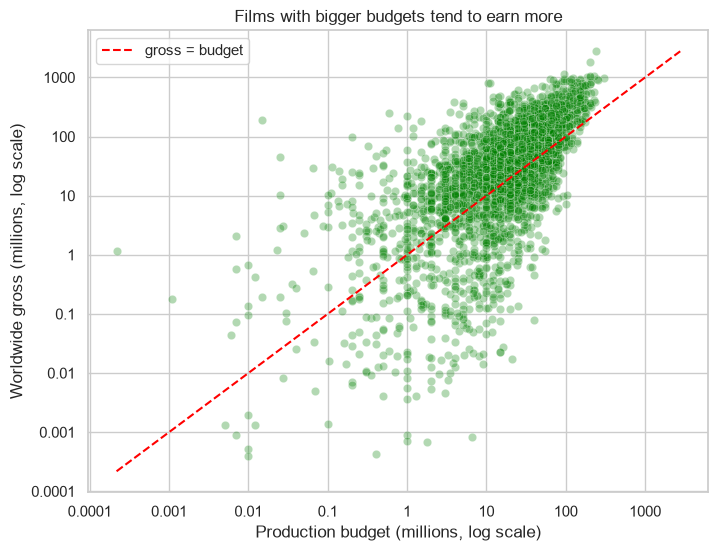

In [ ]:
both = movies[["Production Budget", "Worldwide Gross"]].dropna()
print("Films plotted:", len(both))
print("Films left out (missing budget or gross):", len(movies) - len(both))
print("Pearson correlation:", round(both["Production Budget"].corr(both["Worldwide Gross"]), 3))
print("Spearman correlation:", round(both["Production Budget"].corr(both["Worldwide Gross"], method="spearman"), 3))
print("Share of films that earned less than their budget:", f"{(both['Worldwide Gross'] < both['Production Budget']).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(data=both, x="Production Budget", y="Worldwide Gross", color="green", alpha=0.3, ax=ax)

low, high = both.min().min(), both.max().max()
ax.plot([low, high], [low, high], color="red", linestyle="--", label="gross = budget")

ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(millions)
ax.yaxis.set_major_formatter(millions)

ax.set_title("Films with bigger budgets tend to earn more")
ax.set_xlabel("Production budget (millions, log scale)")
ax.set_ylabel("Worldwide gross (millions, log scale)")
ax.legend()

plt.show()

Each point is one of 3,146 films (55 without a budget or gross are left out). Films with bigger budgets tend to earn more (Spearman correlation 0.678), but 33.5% of the films lie below the red line, which means that they earned less than their budget.

### Chart 2: budget group, gross and gross multiple (question 1)

The medians from the budget-group summary (Part 6) are shown as bars. The two panels are separate because the two money measures answered differently there: total earnings and earnings per unit of budget.

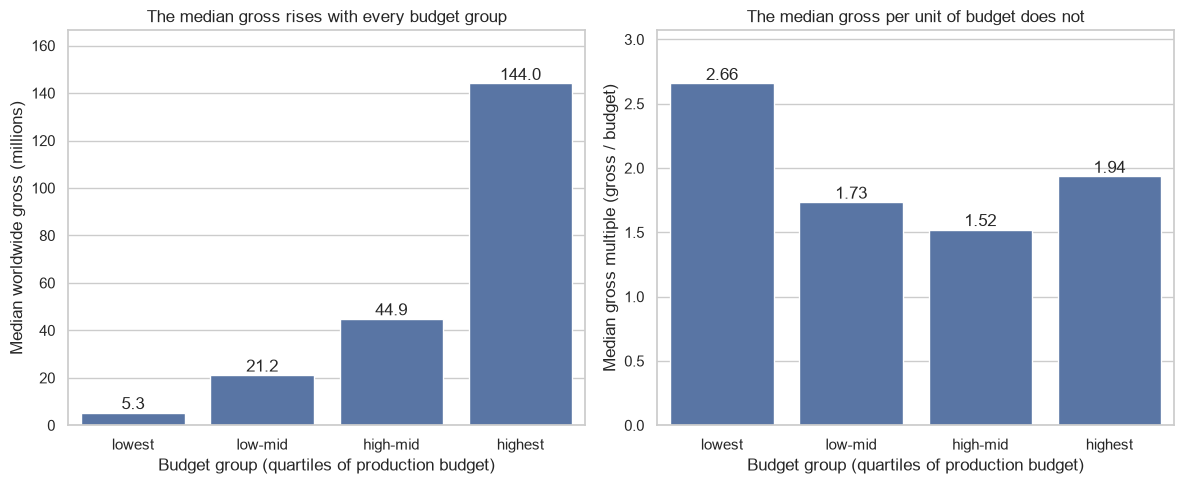

In [ ]:
# `by_budget` has the budget group as its index; reset_index() turns it into a normal column, so seaborn can use it as x
plot_budget = by_budget.reset_index()
# New column showing median gross in millions, so that the axis and the bar labels show 5.3 and not 5,335,137.5
plot_budget["median_gross_millions"] = plot_budget["median_gross"] / 1e6

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=plot_budget, x="Budget Group", y="median_gross_millions", ax=axes[0])
sns.barplot(data=plot_budget, x="Budget Group", y="median_multiple", ax=axes[1])

axes[0].set_title("The median gross rises with every budget group")
axes[0].set_ylabel("Median worldwide gross (millions)")
axes[1].set_title("The median gross per unit of budget does not")
axes[1].set_ylabel("Median gross multiple (gross / budget)")

axes[0].bar_label(axes[0].containers[0], fmt="%.1f")
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")

for ax in axes:
    ax.set_xlabel("Budget group (quartiles of production budget)")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)      # room for the value labels above the bars

plt.tight_layout()
plt.show()

The median worldwide gross rises from 5.3 million in the lowest budget group to 144.0 million in the highest, but the median gross per unit of budget is highest in the lowest group (2.66) and lowest in the high-mid group (1.52).

### Chart 3: Rotten Tomatoes and IMDB ratings (question 2)

The two ratings are plotted against each other on the same 0-10 scale (Part 5). The red diagonal marks equal ratings: films above it were rated higher by audiences than by critics. Films missing either rating cannot be drawn.

Films plotted: 2260
Films left out (a rating is missing): 941
Share of films above the diagonal (IMDB higher): 61.2%


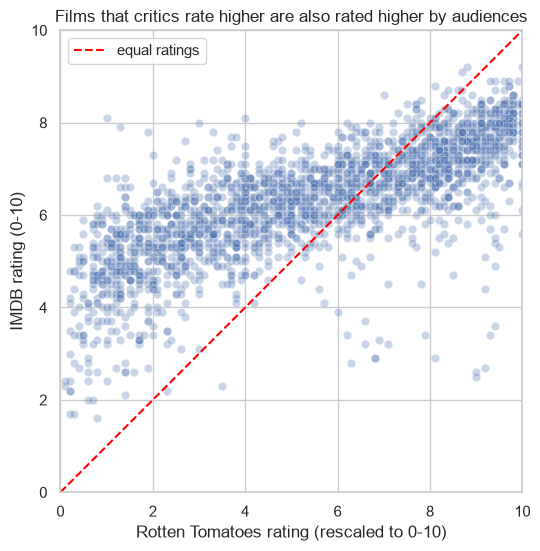

In [ ]:
ratings = movies[["RT Rating (0-10)", "IMDB Rating"]].dropna()

print("Films plotted:", len(ratings))
print("Films left out (a rating is missing):", len(movies) - len(ratings))
print("Share of films above the diagonal (IMDB higher):", f"{(ratings['IMDB Rating'] > ratings['RT Rating (0-10)']).mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 6))

sns.scatterplot(data=ratings, x="RT Rating (0-10)", y="IMDB Rating", alpha=0.3, ax=ax)
ax.plot([0, 10], [0, 10], color="red", linestyle="--", label="equal ratings")

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")                  # equal units on both axes, so the diagonal is a true 45 degree line

ax.set_title("Films that critics rate higher are also rated higher by audiences")
ax.set_xlabel("Rotten Tomatoes rating (rescaled to 0-10)")
ax.set_ylabel("IMDB rating (0-10)")
ax.legend()

plt.show()

Each point is one of 2,260 films (941 without both ratings are left out). The ratings rise together, but 61.2% of the films lie above the red line, which means that audiences rated them higher than critics did.

### Chart 4: the size of the rating gap (question 2)

The correlation says nothing about the level of the ratings, so the distribution of `Rating Gap` is drawn directly. A dotted line marks no gap and a dashed line the median.

Films plotted: 2260
Median gap: -0.8


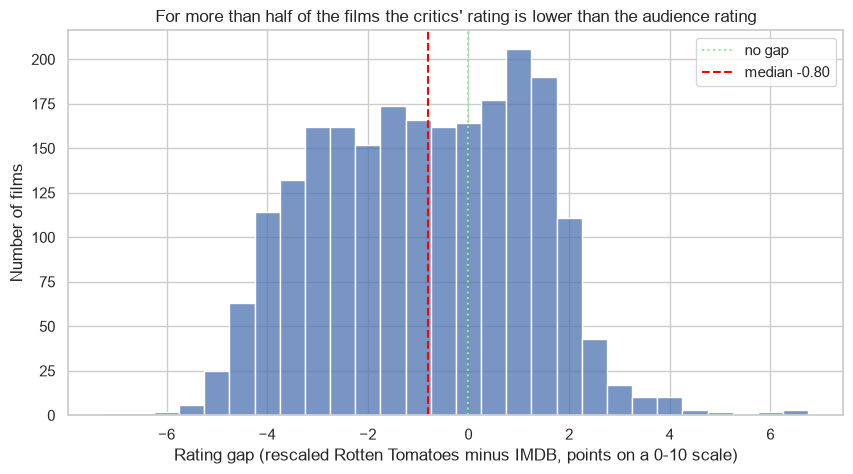

In [ ]:
gap = movies["Rating Gap"].dropna()
print("Films plotted:", len(gap))
print("Median gap:", round(gap.median(), 2))

fig, ax = plt.subplots(figsize=(10, 5))

# Gaps are multiples of 0.1, from -7.1 to 6.5. Bin edges at ±0.25, ±0.75, ... never coincide with a value,
# so each 0.5-wide bin covers exactly 5 possible values, and the range includes every film.
sns.histplot(x=gap, binwidth=0.5, binrange=(-7.25, 6.75), ax=ax)

ax.axvline(0, color="lightgreen", linestyle=":", label="no gap")
ax.axvline(gap.median(), color="red", linestyle="--", label=f"median {gap.median():.2f}")

ax.set_title("For more than half of the films the critics' rating is lower than the audience rating")
ax.set_xlabel("Rating gap (rescaled Rotten Tomatoes minus IMDB, points on a 0-10 scale)")
ax.set_ylabel("Number of films")
ax.legend()

plt.show()

For the 2,260 films with both ratings, the median gap is -0.80 (half of the films are rated at least 0.8 points lower by critics than by audiences), and the gaps are spread widely on both sides of zero.

### Chart 5: genre groups, ratings and money (question 3)

Box plots show the spread inside each genre group, which the medians in Part 6 hide. The groups are sorted by median gross in both panels, and the gross panel uses a logarithmic scale for the reason given in chart 1. The group `Unknown` (films without a genre) is left out, as decided in Part 6.

Films left out (genre group Unknown): 275
                    IMDB Rating  Worldwide Gross
Genre group                                     
Action & adventure          678              725
Thriller & horror           442              454
Comedy & music              847              893
Drama                       738              783
Non-fiction                  41               45


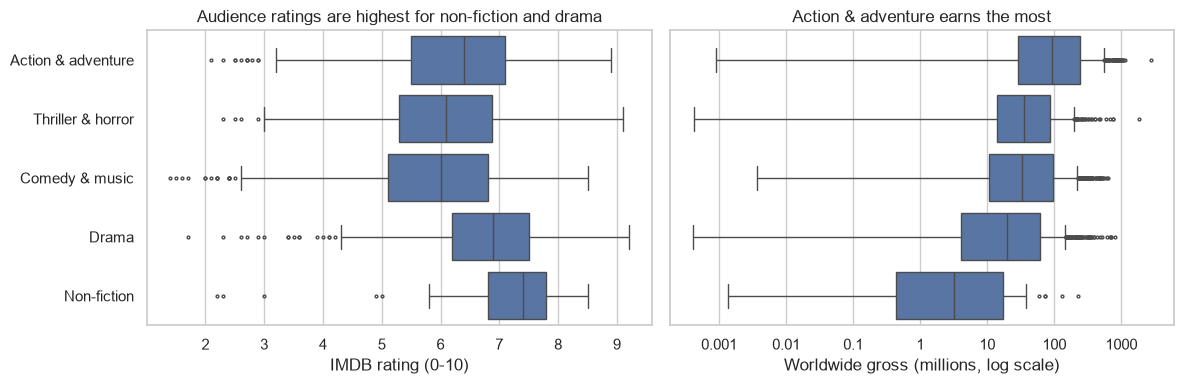

In [ ]:
known = movies[movies["Genre group"] != "Unknown"]
order = by_genre.drop("Unknown").sort_values("median_gross", ascending=False).index

print("Films left out (genre group Unknown):", len(movies) - len(known))
print(known.groupby("Genre group")[["IMDB Rating", "Worldwide Gross"]].count().loc[order])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.boxplot(data=known, x="IMDB Rating", y="Genre group", order=order, fliersize=2, ax=axes[0])
sns.boxplot(data=known, x="Worldwide Gross", y="Genre group", order=order, fliersize=2, ax=axes[1])

axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(millions)

axes[0].set_title("Audience ratings are highest for non-fiction and drama")
axes[1].set_title("Action & adventure earns the most")
axes[0].set_xlabel("IMDB rating (0-10)")
axes[1].set_xlabel("Worldwide gross (millions, log scale)")

for ax in axes:
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

The 275 films without a genre are left out. Audiences rate non-fiction (41 rated films) and drama highest, while action & adventure has by far the highest typical gross, and non-fiction (45 films with a gross) the lowest.